<a href="https://colab.research.google.com/github/MuhammadHafidzrr/galaxy-simulation/blob/main/Galaxy_Simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from IPython.display import clear_output

print("🌌 GALAXY SIMULATION INITIALIZED")
print("Universe is loading...")


🌌 GALAXY SIMULATION INITIALIZED
Universe is loading...


In [3]:

# GALAXY CONFIGURATION
N = 5000
ARMS = 4
RADIUS = 12

np.random.seed(42)

# Distribusi jarak bintang
r = np.random.gamma(shape=2.0, scale=2.0, size=N)
r = np.clip(r, 0, RADIUS)

# Sudut spiral
arm = np.random.randint(0, ARMS, N)
theta = (
    arm * 2 * np.pi / ARMS
    + r * 0.65
    + np.random.normal(0, 0.22, N)
)

# Posisi bintang
x = r * np.cos(theta)
y = r * np.sin(theta)

# Warna berdasarkan jarak
colors = plt.cm.plasma(r / RADIUS)

# Ukuran bintang
sizes = np.random.uniform(0.2, 5, N)

print(f"Total stars: {N}")
print(f"Galaxy arms: {ARMS}")


Total stars: 5000
Galaxy arms: 4


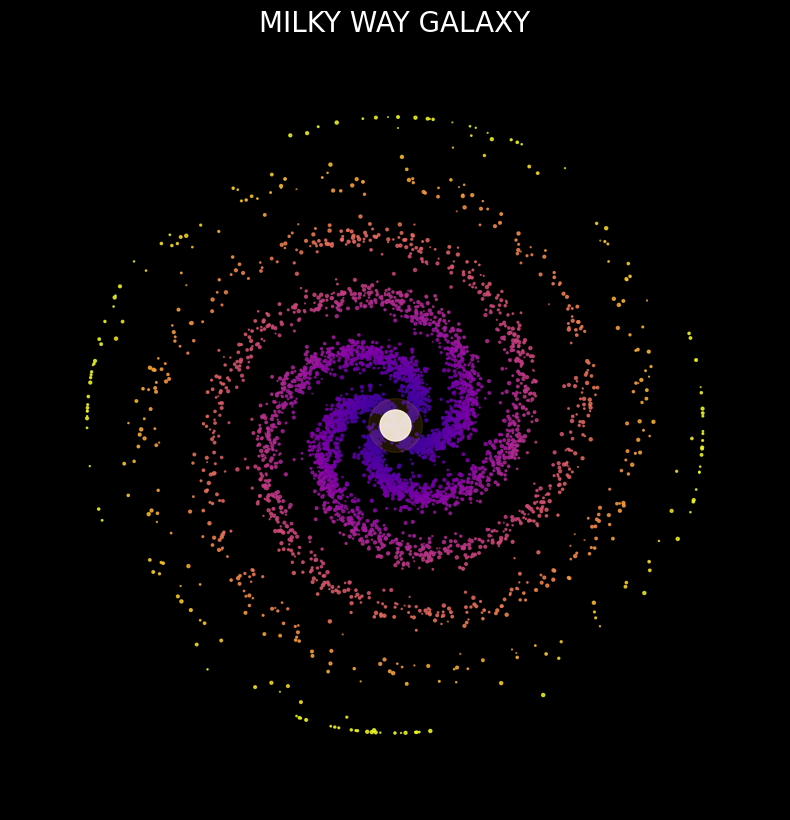

In [4]:

fig, ax = plt.subplots(figsize=(10, 10))

fig.patch.set_facecolor("black")
ax.set_facecolor("black")

# Bintang
ax.scatter(
    x, y,
    s=sizes,
    c=colors,
    alpha=0.8
)

# Inti galaksi
ax.scatter(
    0, 0,
    s=500,
    color="white",
    alpha=0.9
)

ax.scatter(
    0, 0,
    s=1500,
    color="orange",
    alpha=0.12
)

ax.set_xlim(-15, 15)
ax.set_ylim(-15, 15)
ax.set_aspect("equal")
ax.axis("off")

plt.title(
    "MILKY WAY GALAXY",
    color="white",
    fontsize=20
)

plt.show()


In [5]:

fig, ax = plt.subplots(figsize=(8, 8))

fig.patch.set_facecolor("black")
ax.set_facecolor("black")

# Scatter awal
scatter = ax.scatter(
    x, y,
    s=sizes,
    c=colors,
    alpha=0.85
)

# Inti galaksi
ax.scatter(0, 0, s=300, c="white")
ax.scatter(0, 0, s=1000, c="orange", alpha=0.12)

ax.set_xlim(-15, 15)
ax.set_ylim(-15, 15)
ax.set_aspect("equal")
ax.axis("off")

title = ax.set_title(
    "GALAXY SIMULATION",
    color="white",
    fontsize=16
)

# Kecepatan rotasi berbeda berdasarkan radius
omega = 0.8 / np.sqrt(r + 0.5)

def update(frame):
    angle = omega * frame * 0.035

    new_x = x * np.cos(angle) - y * np.sin(angle)
    new_y = x * np.sin(angle) + y * np.cos(angle)

    scatter.set_offsets(np.column_stack((new_x, new_y)))

    title.set_text(f"MILKY WAY | FRAME {frame}")

    return scatter, title

ani = FuncAnimation(
    fig,
    update,
    frames=200,
    interval=30,
    blit=True
)

plt.close(fig)

display(HTML(ani.to_jshtml()))
